In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub

# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/mkhoirulmustaqim/student-depression-detection-dataset/Student Depression Detection Dataset/Student_Depression_Dataset.csv
/kaggle/input/datasets/mkhoirulmustaqim/student-depression-detection-dataset/Student Depression Detection Dataset/Student_Depression_Dataset.xlsx


In [2]:
df=pd.read_csv("/kaggle/input/datasets/mkhoirulmustaqim/student-depression-detection-dataset/Student Depression Detection Dataset/Student_Depression_Dataset.csv")

In [3]:
df.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


In [4]:
df.isnull().sum()

Gender                 0
Age                    0
Family_background      0
Relationship_status    0
Marital_status         0
Living_style           0
Current_semester       0
CGPA                   0
friend_circle          0
Health_condition       0
Cost_without_study     0
Home_division          0
Depression             0
dtype: int64

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   object 
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   object 
 3   Relationship_status  4464 non-null   object 
 4   Marital_status       4464 non-null   object 
 5   Living_style         4464 non-null   object 
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   object 
 9   Health_condition     4464 non-null   object 
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   object 
 12  Depression           4464 non-null   object 
dtypes: float64(1), int64(3), object(9)
memory usage: 453.5+ KB


In [6]:
df['Depression'].value_counts(normalize=True)

Depression
No     0.730959
Yes    0.269041
Name: proportion, dtype: float64

In [7]:
cat_cols=df.select_dtypes(include='object')
num_cols=df.select_dtypes(exclude='object') 

In [8]:
for i in cat_cols:
    print(i,"-->",df[i].nunique())

Gender --> 2
Family_background --> 3
Relationship_status --> 3
Marital_status --> 3
Living_style --> 2
friend_circle --> 2
Health_condition --> 4
Home_division --> 8
Depression --> 2


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

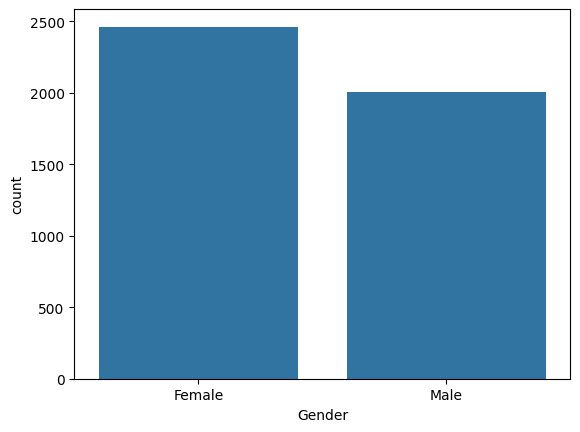

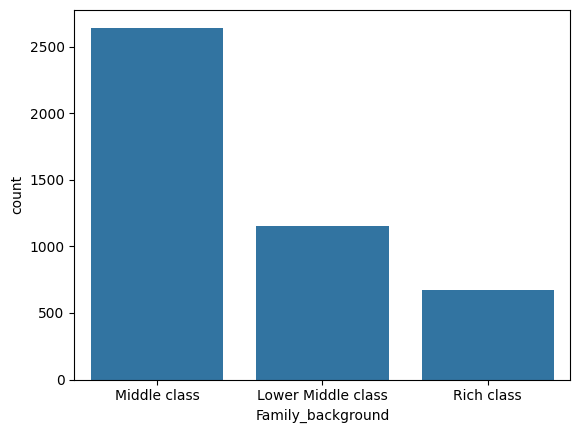

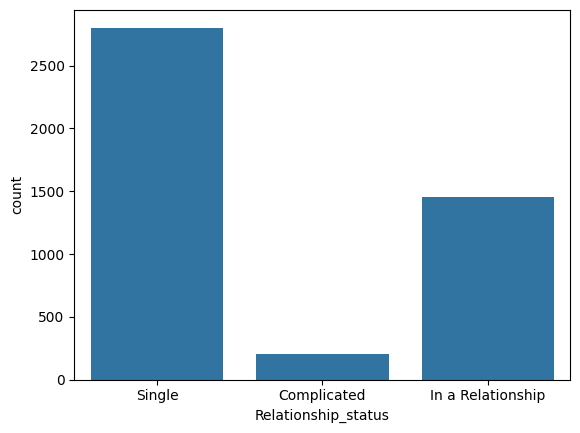

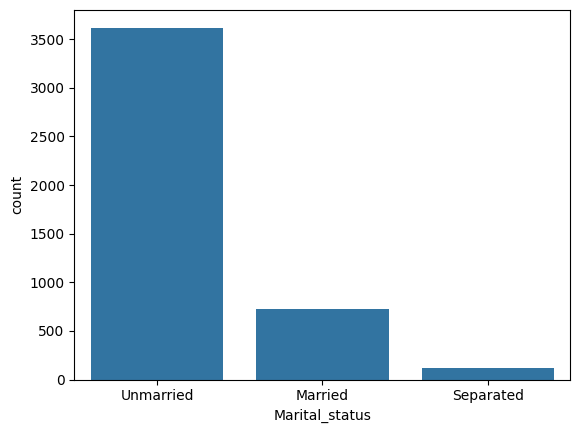

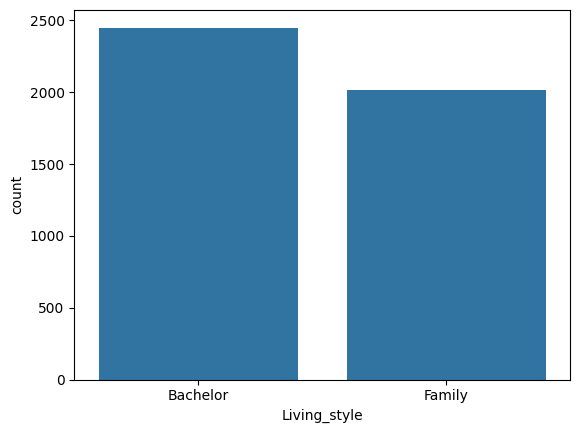

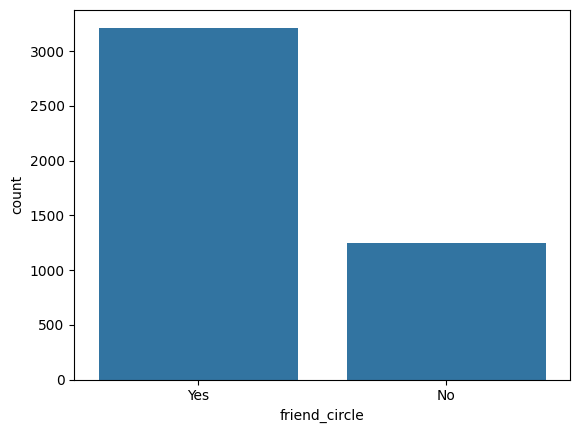

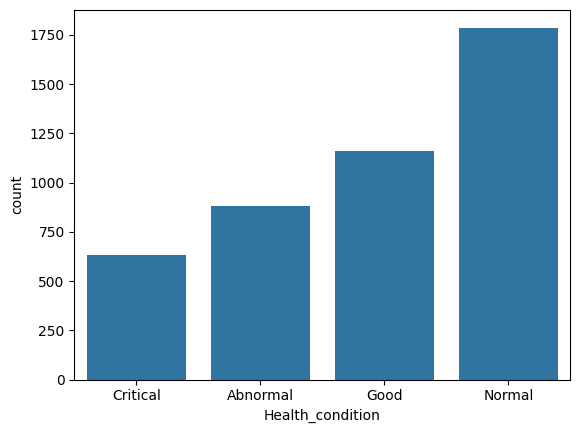

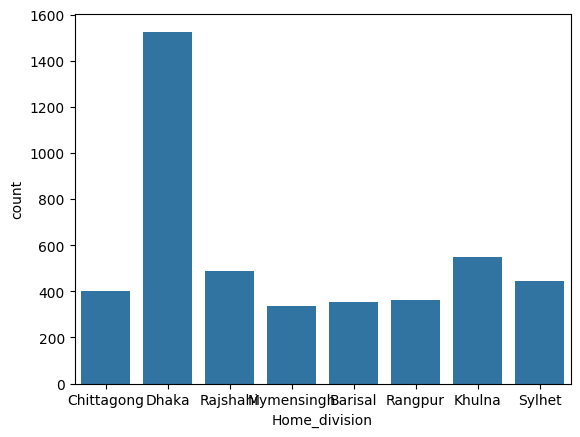

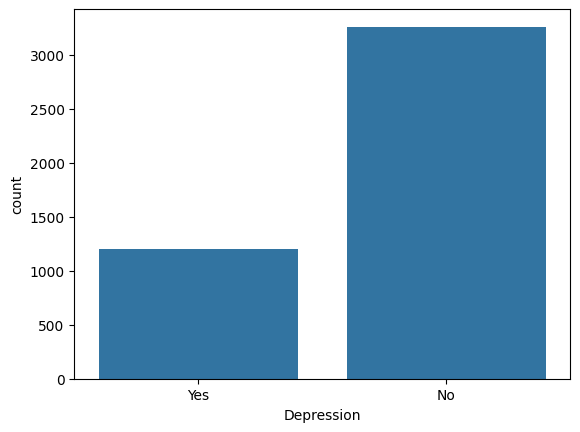

In [10]:
for i in cat_cols:
    sns.countplot(x=i,data=df)
    plt.show()

In [11]:

from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
for i in cat_cols:
    df[i]=le.fit_transform(df[i])+1
   

In [12]:
num_cols.describe()

,Age,Current_semester,CGPA,Cost_without_study
count,4464.000000,4464.000000,4464.000000,4464.000000
mean,22.619176,5.401210,3.412753,11242.978271
std,2.022980,2.578476,0.385605,6640.144019
min,17.000000,0.000000,2.250000,0.000000
25%,21.000000,3.000000,3.150000,6100.000000
50%,23.000000,5.000000,3.490000,9500.000000
75%,24.000000,7.000000,3.700000,15439.000000
max,28.000000,13.000000,4.000000,32000.000000


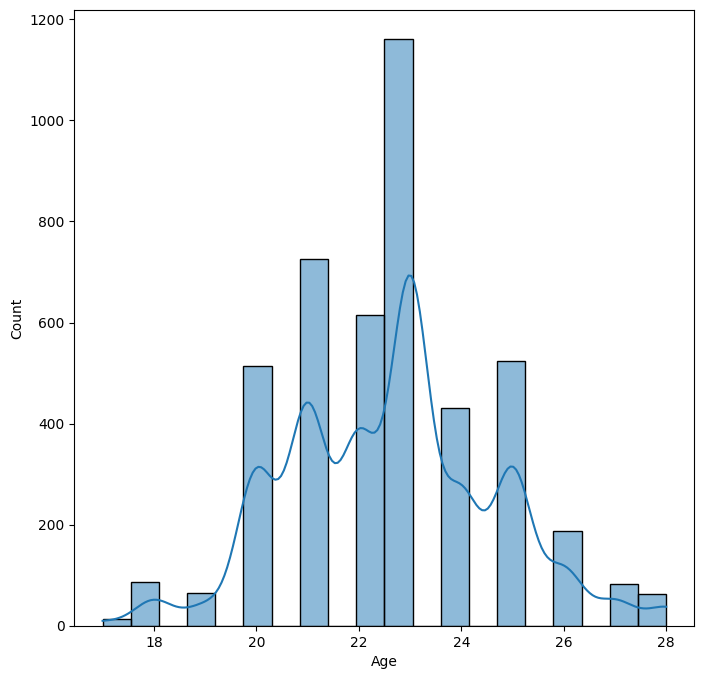

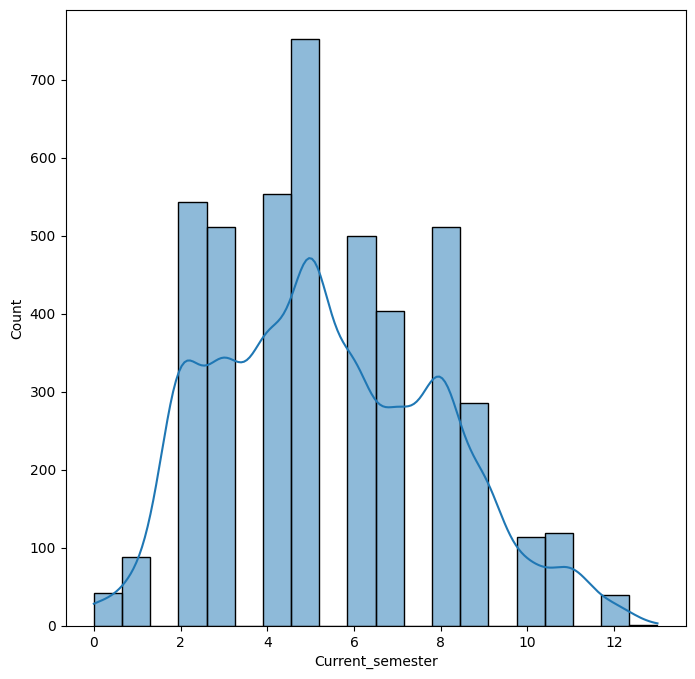

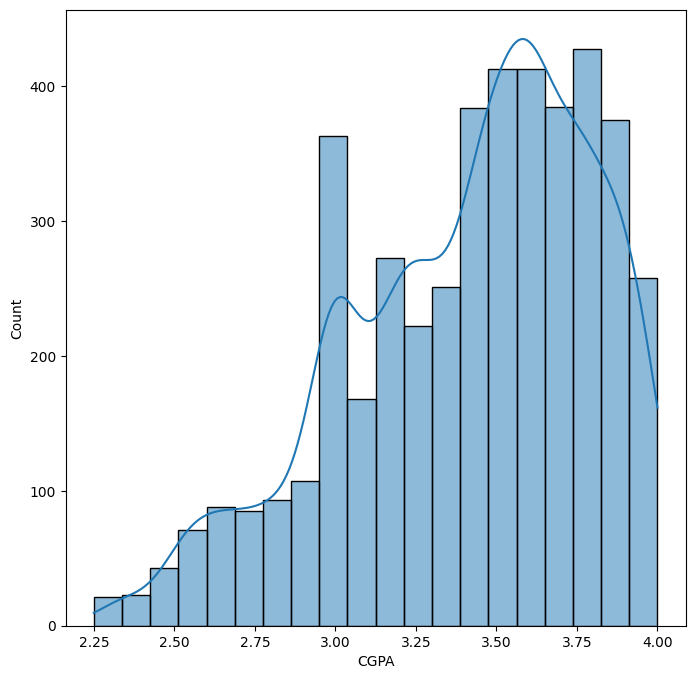

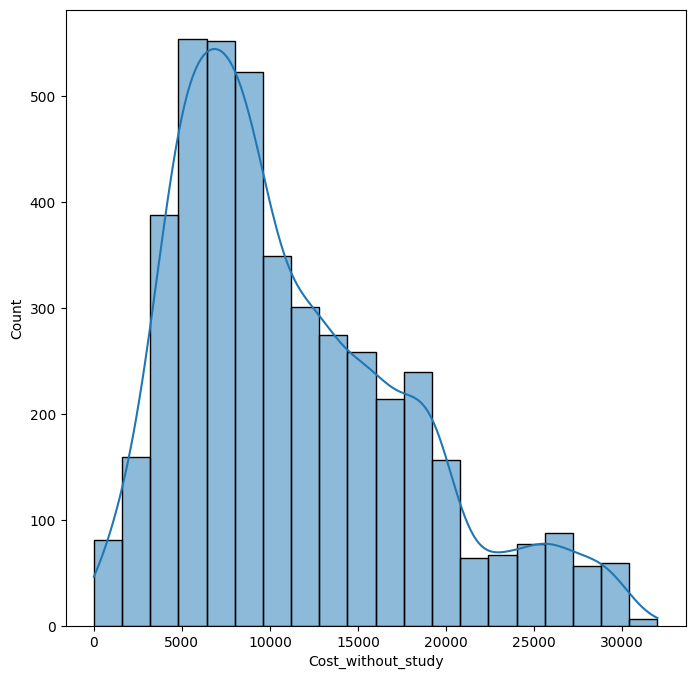

In [13]:
for i in num_cols:
    plt.figure(figsize=(8,8))
    sns.histplot(x=df[i],kde=True,bins=20)
    plt.show()

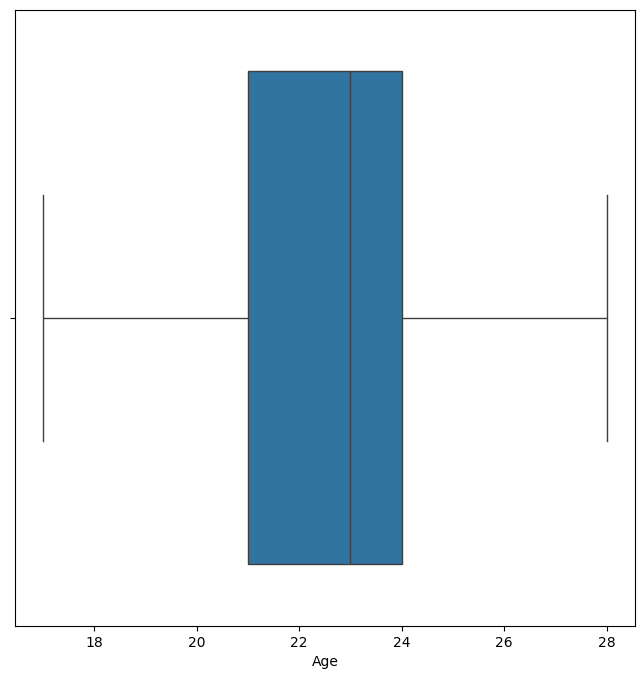

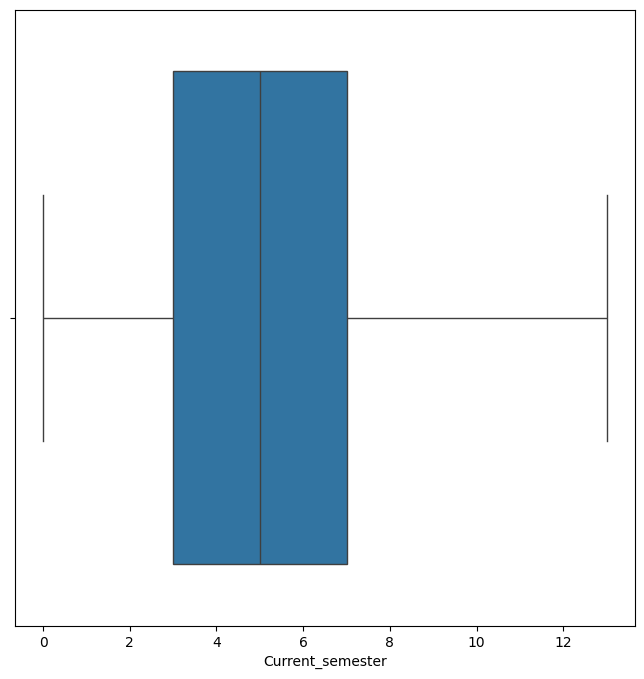

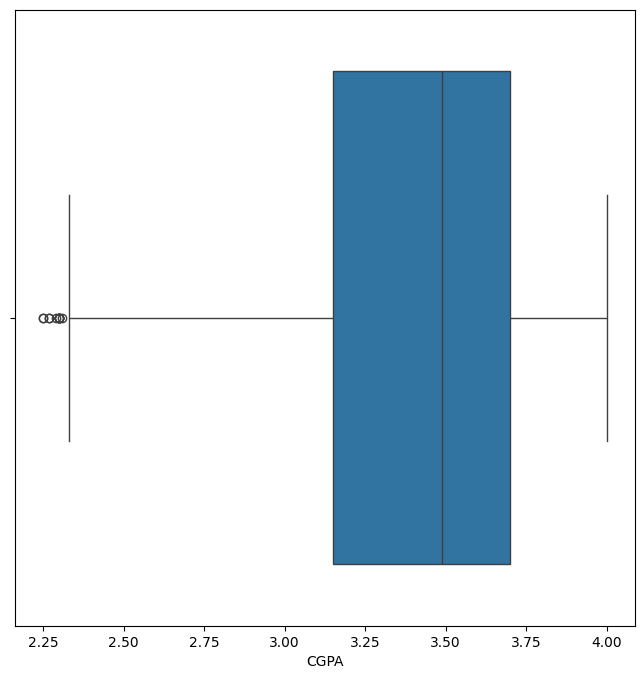

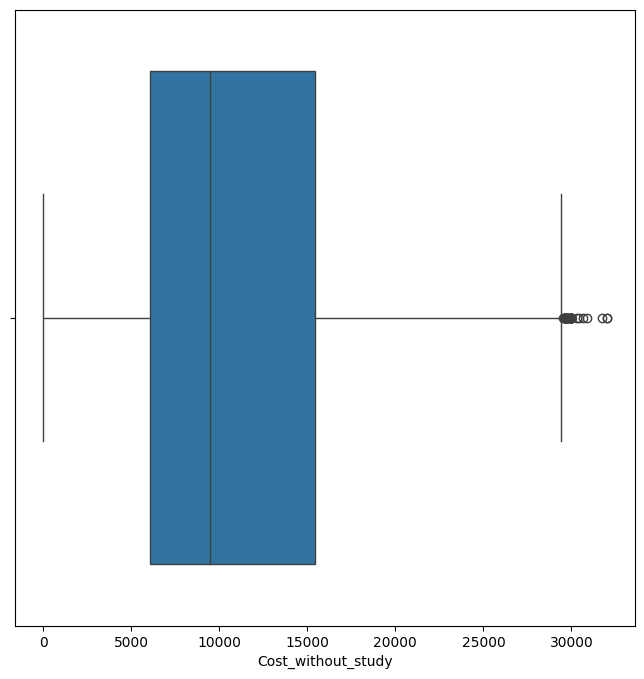

In [14]:
for i in num_cols:
    plt.figure(figsize=(8,8))
    sns.boxplot(x=df[i])

In [15]:
for i in num_cols:

    Q1=df[i].quantile(0.25)
    Q3=df[i].quantile(0.75)
    IQR=Q3-Q1
 
    lower_bound=Q1-1.5*IQR
    higher_bound=Q3+1.5*IQR

    outliers=df[(df[i]>higher_bound)|(df[i]<lower_bound)]

    print(f"{i}\n")
    print(lower_bound)
    print(higher_bound)
    print(len(outliers))
    print("Outlier Percentage:", (len(outliers) / len(df)) * 100)
    print("\n")

Age

16.5
28.5
0
Outlier Percentage: 0.0


Current_semester

-3.0
13.0
0
Outlier Percentage: 0.0


CGPA

2.3249999999999993
4.525
12
Outlier Percentage: 0.2688172043010753


Cost_without_study

-7908.5
29447.5
36
Outlier Percentage: 0.8064516129032258




In [16]:
print(df[['CGPA','Cost_without_study']].describe())

              CGPA  Cost_without_study
count  4464.000000         4464.000000
mean      3.412753        11242.978271
std       0.385605         6640.144019
min       2.250000            0.000000
25%       3.150000         6100.000000
50%       3.490000         9500.000000
75%       3.700000        15439.000000
max       4.000000        32000.000000


In [17]:
print(df[['CGPA','Cost_without_study']].skew())

CGPA                 -0.604811
Cost_without_study    0.846608
dtype: float64


In [18]:
import numpy as np
# df['CGPA']=np.cbrt(df['CGPA'])
from sklearn.preprocessing import PowerTransformer

pt = PowerTransformer(method='yeo-johnson')

df['CGPA'] = pt.fit_transform(
    df[['CGPA']]
).ravel()

print(df['CGPA'].skew())

-0.11224877923930425


In [19]:
print(df[['CGPA']].skew())

CGPA   -0.112249
dtype: float64


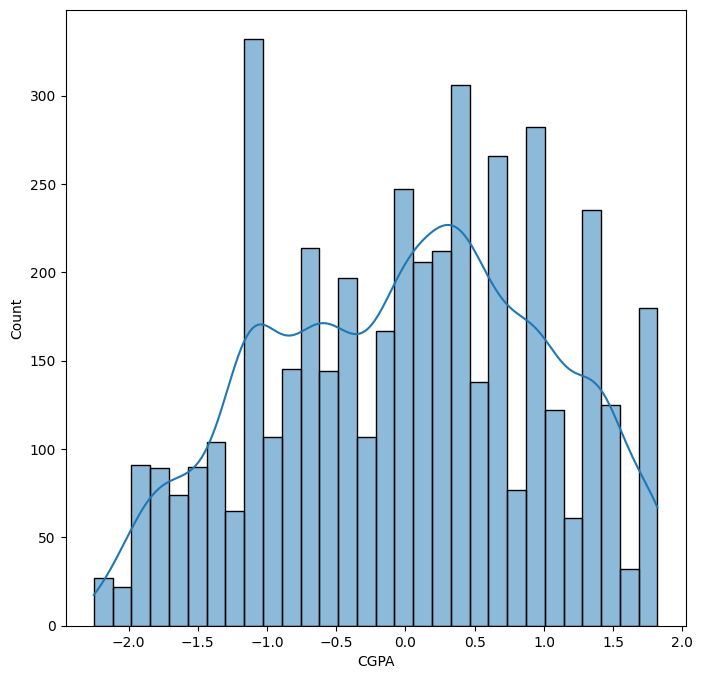

In [20]:
plt.figure(figsize=(8,8))
sns.histplot(x=df['CGPA'],bins=30,kde=True)
plt.show()

In [21]:
df['Cost_without_study']=pt.fit_transform(df[['Cost_without_study']]).ravel()
print(df['Cost_without_study'].skew())

0.002812067227456849


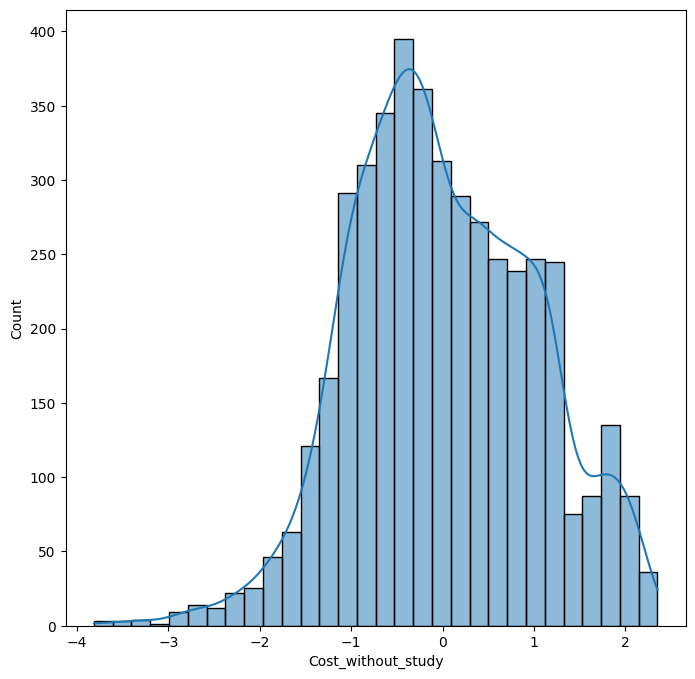

In [22]:
plt.figure(figsize=(8,8))
sns.histplot(x=df['Cost_without_study'],bins=30,kde=True)
plt.show()

In [23]:
df.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,1,22,2,3,3,1,8,-0.087364,2,2,0.006379,2,2
1,2,19,2,3,3,1,2,0.729429,2,1,0.537145,2,2
2,2,23,2,3,3,2,8,-0.480578,1,1,0.744526,3,2
3,2,20,2,1,3,2,2,0.965794,1,3,0.977005,3,1
4,1,21,2,3,3,2,1,1.819804,1,1,0.893630,3,2


In [24]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
for i in cat_cols:
    df[i]=le.fit_transform(df[i])

In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   int64  
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   int64  
 3   Relationship_status  4464 non-null   int64  
 4   Marital_status       4464 non-null   int64  
 5   Living_style         4464 non-null   int64  
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   int64  
 9   Health_condition     4464 non-null   int64  
 10  Cost_without_study   4464 non-null   float64
 11  Home_division        4464 non-null   int64  
 12  Depression           4464 non-null   int64  
dtypes: float64(2), int64(11)
memory usage: 453.5 KB


In [26]:
y=df['Depression']
x=df.drop(columns='Depression',axis=1)

In [27]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.8,random_state=42)

In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
model1=LogisticRegression(max_iter=2000)
model2=RandomForestClassifier()

model1.fit(x_train,y_train)
model2.fit(x_train,y_train)

pred1=model1.predict(x_test)
pred2=model2.predict(x_test)

In [29]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

acc1 = accuracy_score(y_test,pred1)
acc2 = accuracy_score(y_test,pred2)

print("Accuracy of Logistic regression is: ",acc1)
print("Accuracy of Random Forest regression is: ",acc2)

print("\nClassification Report of Logistic regression is: \n",classification_report(y_test,pred1))
print("Classification Report of Random Forest regression is: \n",classification_report(y_test,pred2))

Accuracy of Logistic regression is:  0.8628219484882419
Accuracy of Random Forest regression is:  0.979003359462486

Classification Report of Logistic regression is: 
               precision    recall  f1-score   support

           0       0.90      0.91      0.91      2644
           1       0.75      0.72      0.73       928

    accuracy                           0.86      3572
   macro avg       0.82      0.82      0.82      3572
weighted avg       0.86      0.86      0.86      3572

Classification Report of Random Forest regression is: 
               precision    recall  f1-score   support

           0       0.98      0.99      0.99      2644
           1       0.97      0.95      0.96       928

    accuracy                           0.98      3572
   macro avg       0.98      0.97      0.97      3572
weighted avg       0.98      0.98      0.98      3572

